# Titanic - Machine Learning from Disaster

## Import thư viện

In [5]:
# Imports
import warnings
warnings.filterwarnings('ignore')

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_auc_score

## Load dữ liệu

In [8]:
# Load data 
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

## Preview data

In [9]:
print('Loaded:', train_df.shape, test_df.shape)
train_df.head()

Loaded: (891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [10]:
test_df.tail()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


## Exploratory Data Analysis - EDA

In [13]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [12]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


In [14]:
def display_missing_data(df):
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    percent = (missing / len(df)) * 100
    print(pd.DataFrame({'Missing Values': missing, 'Percent (%)': percent.round(2)}))

display_missing_data(train_df)

          Missing Values  Percent (%)
Cabin                687        77.10
Age                  177        19.87
Embarked               2         0.22


In [15]:
display_missing_data(test_df)

       Missing Values  Percent (%)
Cabin             327        78.23
Age                86        20.57
Fare                1         0.24


In [16]:
def best_features_for_imputation(df, target='Age', top=10):
    """
    Phân tích mối tương quan giữa 1 feature (vd: Age)
    với tất cả các feature khác trong dataframe để gợi ý 
    nên dùng cột nào để điền missing values.
    ----------------------------------------------------
    df: DataFrame
    target: tên cột muốn xem tương quan (vd 'Age')
    top: số lượng feature top đầu cần hiển thị
    """
    corrs = {}
    for col in df.columns:
        if col == target:
            continue

        try:
            # Nếu là numeric -> dùng Spearman correlation
            if np.issubdtype(df[col].dropna().dtype, np.number):
                corr = spearmanr(df[target], df[col], nan_policy='omit')[0]
            else:
                # Nếu là object -> factorize (chuyển sang mã số)
                corr = spearmanr(df[target], pd.factorize(df[col])[0], nan_policy='omit')[0]
            corrs[col] = abs(corr)
        except Exception as e:
            continue

    # Sắp xếp giảm dần
    corrs_sorted = pd.Series(corrs).sort_values(ascending=False)
    result = corrs_sorted.head(top).to_frame('Spearman Corr (|r|)')
    print(f"\nTop {top} features liên quan mạnh nhất đến '{target}':\n")
    print(result)

### Target Variable: `Survived`

In [18]:
survival_counts = train_df['Survived'].value_counts(normalize=True)

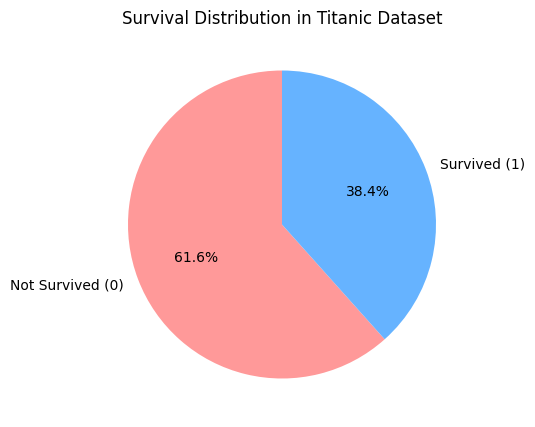

In [19]:
plt.figure(figsize=(5,5))
plt.pie(
    survival_counts,
    labels=['Not Survived (0)', 'Survived (1)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#ff9999','#66b3ff']
)
plt.title('Survival Distribution in Titanic Dataset')
plt.show()

Chỉ có khoảng 38.4% hành khách sống sót trong thảm họa Titanic.

- Phân bố của các Features

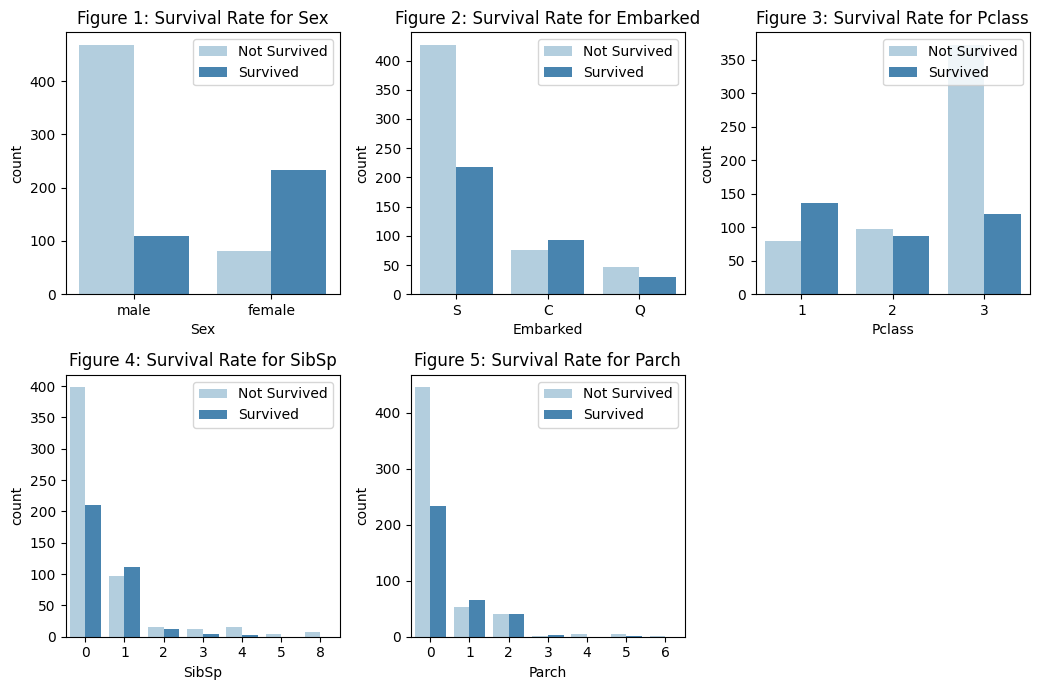

In [20]:
cols = [ 'Sex', 'Embarked', 'Pclass', 'SibSp', 'Parch'] 

n_rows = 2
n_cols = 3

fig, ax = plt.subplots(n_rows, n_cols, figsize=(n_cols*3.5, n_rows*3.5))

for r in range(0, n_rows):
    for c in range(0, n_cols):
        i = r*n_cols + c
        if i < len(cols):
            ax_i = ax[r,c]
            sns.countplot(data=train_df, x=cols[i], hue='Survived', palette='Blues', ax=ax_i)
            ax_i.set_title(f'Figure {i+1}: Survival Rate for {cols[i]}')
            ax_i.legend(title='', loc='upper right', labels=['Not Survived', 'Survived'])
ax.flat[-1].set_visible(False)
plt.tight_layout()

**Tỉ lệ sống sót**:
- Fig 1: Tỉ lệ sống sót của nữ giới cao hơn nam giới.
- Fig 2: Đa phần mọi người đi đến Southampton, và cũng có lượng người không sống sót cao nhất.
- Fig 3: Vé hạng 1 có tỉ lệ sống sót cao hơn.
- Fig 4: Những người với `SibSp` bằng 0 hầu hết sẽ không sống sót, số lượng hành khách đi với 1-2 thành viên gia đình có cơ hội sống sót cao hơn.
- Fig 5: Những người với `Parch` bằng 0 đa phần sẽ không sống sót, số lượng hành khách đi với 1-2 thành viên gia đình có cơ hội sống sót cao hơn.

- Age

<Axes: xlabel='Age', ylabel='Count'>

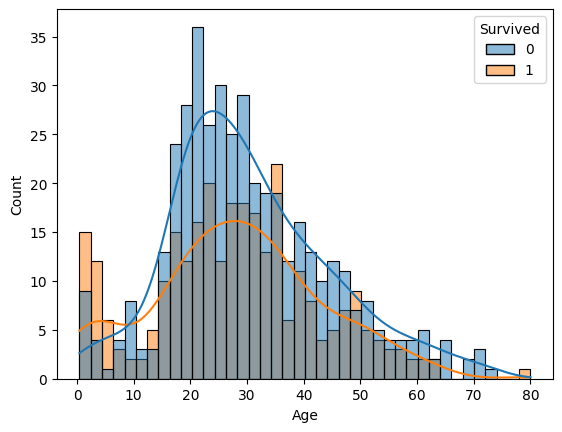

In [21]:
sns.histplot(data=train_df, x='Age', hue='Survived', bins=40, kde=True)

- Đa phần hành khách có độ tuổi từ 18-40 tuổi.
- Trẻ em có nhiều cơ hội sống sót hơn những độ tuổi khác

- Fare

<Axes: xlabel='Fare', ylabel='Count'>

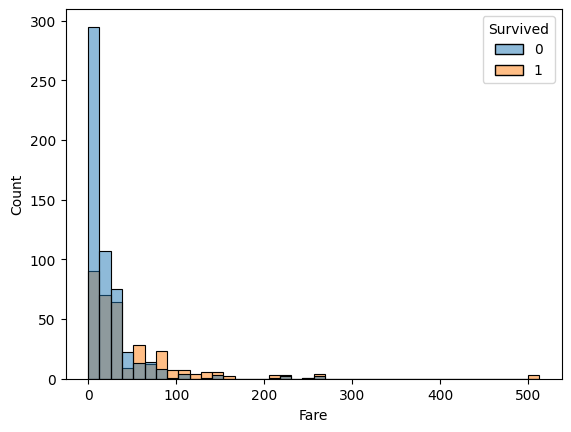

In [22]:
sns.histplot(data=train_df, x='Fare', hue='Survived', bins=40)

In [23]:
best_features_for_imputation(train_df, target='Survived', top=20)


Top 20 features liên quan mạnh nhất đến 'Survived':

             Spearman Corr (|r|)
Sex                     0.543351
Pclass                  0.339668
Fare                    0.323736
Cabin                   0.316508
Parch                   0.138266
Embarked                0.130585
SibSp                   0.088879
Age                     0.052565
Ticket                  0.039201
Name                    0.005007
PassengerId             0.005007


**Ta có các biến liên quan đến `Survived` và không bị missing:**
- Sex
- Pclass
- SibSp / Parch
- Name

## Feature Engineering (Các features không bị missing)

#### Tạo thêm các biến mới giúp mô hình phân tích chuẩn xác và mạnh hơn

- `Title`: Phản ánh giới tính, địa vị, tầng lớp xã hội.
- `IsFemale`: Giới tính nữ được ưu tiên hơn.
- `FamilySize`: Quy mô gia đình ảnh hưởng tỉ lệ sống, đi cùng thành viên gia đình có tỉ lệ sống sót cao hơn.
- `IsChild`: Đánh dấu trẻ em (dưới 12 tuổi). Trong Titanic, trẻ em thường được cứu trước theo nguyên tắc “women and children first”.
- `IsMother`: Đánh dấu phụ nữ trưởng thành có con đi cùng. Mẹ thường được ưu tiên cứu cùng con.

In [24]:
# Feature engineering
def extract_title(name):
    m = re.search(r',\s*([^\.]+)\.', name)
    return m.group(1).strip() if m else ''

title_map = {
    'Capt': 'Officer', 'Col': 'Officer', 'Major': 'Officer', 'Dr': 'Officer', 'Rev': 'Officer',
    'Don': 'Royalty', 'Sir': 'Royalty', 'Lady': 'Royalty', 'the Countess': 'Royalty', 'Jonkheer': 'Royalty', 'Dona': 'Royalty'
}

for df in [train_df, test_df]:
    # --- Title (Name) ---
    df['Title'] = df['Name'].apply(extract_title)
    df['Title'] = df['Title'].replace(['Mlle','Ms'],'Miss')
    df['Title'] = df['Title'].replace(['Mme'],'Mrs')
    df['Title'] = df['Title'].replace(title_map)
    rare = df['Title'].value_counts()[df['Title'].value_counts() < 10].index
    df['Title'] = df['Title'].replace(list(rare), 'Other')

    # --- Family (SibSp/Parch) ---
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

    # --- Special groups ---
    df['IsChild'] = (df['Age'] < 12).astype(int)
    df['IsMother'] = ((df['Sex'] == 'female') & (df['Parch'] > 0) & (df['Age'] > 18) & (df['Title'] == 'Mrs')).astype(int)

## Filling missing values

In [25]:
display_missing_data(train_df)

          Missing Values  Percent (%)
Cabin                687        77.10
Age                  177        19.87
Embarked               2         0.22


- Trong file train.csv, chỉ có 2 giá trị bị thiếu (NaN) trên tổng 891 dòng —
tức là 0.2% dữ liệu → rất ít, không ảnh hưởng lớn đến phân phối.
- Chọn mode() là giá trị xuất hiện nhiều nhất trong cột để điền "giá trị đại diện" cho `Embarked`.

In [26]:
display_missing_data(test_df)

       Missing Values  Percent (%)
Cabin             327        78.23
Age                86        20.57
Fare                1         0.24


- Fare chỉ thiếu 1 giá trị → nên điền theo median.

In [27]:
best_features_for_imputation(train_df, target='Fare', top=10)


Top 10 features liên quan mạnh nhất đến 'Fare':

            Spearman Corr (|r|)
Pclass                 0.688032
Cabin                  0.532923
FamilySize             0.528907
SibSp                  0.447113
Parch                  0.410074
Survived               0.323736
Title                  0.303792
Sex                    0.259593
Ticket                 0.258902
IsMother               0.183694


- Ta thấy Pclass liên quan mạnh nhất đến `Fare` nên điền missing value của `Fare` bằng median của nhóm Pclass.

Ta thấy được trong các features có liên quan đến `Age`,:
- Parch: Hạng vé, tầng lớp xã hội. Người giàu (Pclass=1) thường lớn tuổi hơn.
- Chức danh (Mr, Miss, Dr, Master...). Phản ánh tuổi rõ nhất (Mr > Master, Miss trẻ hơn Mrs).
- Giới tính. Nam/Nữ có độ tuổi trung bình khác nhau trong từng nhóm xã hội
- Khi điền giá trị thiếu (Age), ta muốn ước lượng gần đúng độ tuổi thật của hành khách, ta chọn `Sex + Pclass + Title` là nhóm tối ưu nhất

In [28]:
# Fill missing values
for df in [train_df, test_df]:
    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

    df['Fare'] = df.groupby('Pclass')['Fare'].transform(lambda x: x.fillna(x.median()))
    
    df['Age'] = df.groupby(['Sex','Pclass','Title'])['Age'].transform(lambda x: x.fillna(x.median()))

    # --- Chuẩn hóa log ---
    df['Fare'] = np.log1p(df['Fare'])
    df['Age'] = np.log1p(df['Age'])

## Feature Engineering (Các biến khác)

In [29]:
for df in [train_df, test_df]:

    df['HasCabin'] = df['Cabin'].notna().astype(int)

    df['Age*Pclass'] = df['Age'] * df['Pclass']

    # --- Cabin / Deck ---
    df['Deck'] = df['Cabin'].astype(str).str[0]
    df['Deck'] = df['Deck'].replace('n', 'U')  # 'U' = Unknown

    # --- Interaction features ---
    df['Fare_Pclass'] = df['Fare'] / df['Pclass']

    df['TicketPrefix'] = df['Ticket'].apply(lambda x: re.split(r'\s|\.', str(x))[0])
    df['TicketPrefix'] = df['TicketPrefix'].apply(lambda x: x if x.isalpha() else 'NUM')

- `HasCabin`: Có Cabin hay không. Người có cabin → hạng vé cao → tầng lớp giàu có.
- `Deck`: Boong (deck) tàu – ký tự đầu của Cabin (A, B, C, D...). Deck thấp → gần đáy tàu → nguy hiểm hơn.
- `Age*Pclass`: Kết hợp tuổi và hạng vé – phản ánh “tầng lớp xã hội theo tuổi”.
- `Fare_Pclass`: Giá vé chia theo hạng vé.
- `TicketPrefix`: Phần đầu vé cho biết hãng tàu hoặc loại vé.

### Các features để mô hình phân tích

In [30]:
# Prepare features
feature_cols = [
    'Pclass','Sex','Age','Fare','Embarked','Title','FamilySize','IsChild','IsMother',
    'Deck','HasCabin','Fare_Pclass','Age*Pclass','TicketPrefix'
]
x = train_df[feature_cols]
y = train_df['Survived']
x_test_final = test_df[feature_cols]

### Preprocess pipeline

In [31]:
# Preprocessor (ColumnTransformer)
num_features = [
    'Age','Fare','FamilySize','Fare_Pclass','Age*Pclass'
]
cat_features = [
    'Pclass','Sex','Embarked','Title','IsChild','IsMother',
    'Deck','HasCabin','TicketPrefix'
]

num_transformer = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer([('num', num_transformer, num_features), ('cat', cat_transformer, cat_features)])

## Models Training

**Các mô hình dùng để phân tích**: `Logistic Regression`, `Random Forest`, `XGBoost`, `SVM`

In [32]:
# --- Khởi tạo các pipeline ---
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=1000,random_state=42,C=1.0,solver='lbfgs'))
    ]),

    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(random_state=42, n_jobs=-1,n_estimators=500, max_depth=5,min_samples_split=5, min_samples_leaf=3))
    ]),

    'XGBoost': Pipeline([
        ('preprocessor', preprocessor),
        ('model', XGBClassifier(random_state=42,eval_metric='logloss',n_jobs=-1,n_estimators=120,max_depth=2,learning_rate=0.08,subsample=0.6,colsample_bytree=0.6,reg_lambda=3,reg_alpha=2))
    ]),

    'SVM': Pipeline([
        ('preprocessor', preprocessor),
        ('model', SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42))
    ])
}

### Đánh giá từng model bằng cross-validation

In [33]:
cv = StratifiedKFold(n_splits=15, shuffle=True, random_state=42)

for name, model in models.items():
    acc = cross_val_score(model, x, y, cv=cv, scoring='accuracy').mean()
    f1 = cross_val_score(model, x, y, cv=cv, scoring='f1').mean()
    auc = cross_val_score(model, x, y, cv=cv, scoring='roc_auc').mean()

    print(f"{name} CV Results:")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  F1 Score: {f1:.4f}")
    print(f"  ROC AUC:  {auc:.4f}")
    print("-" * 35)

Logistic Regression CV Results:
  Accuracy: 0.8238
  F1 Score: 0.7625
  ROC AUC:  0.8743
-----------------------------------
Random Forest CV Results:
  Accuracy: 0.8304
  F1 Score: 0.7579
  ROC AUC:  0.8695
-----------------------------------
XGBoost CV Results:
  Accuracy: 0.8237
  F1 Score: 0.7648
  ROC AUC:  0.8753
-----------------------------------
SVM CV Results:
  Accuracy: 0.8328
  F1 Score: 0.7635
  ROC AUC:  0.8749
-----------------------------------


### Đánh giá từng model bằng hàm train_test_split

In [35]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.2, random_state=42)
for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_val)
    y_prob = model.predict_proba(x_val)[:,1]

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_prob)

    print(f"{name} Results:")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  F1 Score: {f1:.4f}")
    print(f"  ROC AUC:  {auc:.4f}")
    print("-" * 35)

Logistic Regression Results:
  Accuracy: 0.8156
  F1 Score: 0.7724
  ROC AUC:  0.8880
-----------------------------------
Random Forest Results:
  Accuracy: 0.8101
  F1 Score: 0.7536
  ROC AUC:  0.9001
-----------------------------------
XGBoost Results:
  Accuracy: 0.8156
  F1 Score: 0.7755
  ROC AUC:  0.8950
-----------------------------------
SVM Results:
  Accuracy: 0.8212
  F1 Score: 0.7746
  ROC AUC:  0.8656
-----------------------------------


### Chọn mô hình tốt nhất

In [37]:
best_model = models['SVM']
best_model.fit(x, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

## Xuất ra file kết quả

In [38]:
# Prepare submission (predict on test)
try:
    preds = best_model.predict(x_test_final)
    submission = pd.DataFrame({
        'PassengerId': test_df['PassengerId'], 
        'Survived': preds.astype(int)
    })
    submission.to_csv('submission.csv', index=False)
    print("File 'submission.csv' created.")
except Exception as e:
    print('Không thể tạo submission tự động:', e)


File 'submission.csv' created.


In [29]:
# !jupyter nbconvert --to script titanic_test.ipynb

# Titanic: Machine Learning from Disaster bằng PyTorch

## Import thư viện

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import wandb

print("PyTorch:", torch.__version__)

## Load data

In [40]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Số hành khách trong train:", len(train))
print("Số hành khách trong test :", len(test))

train.head()

Số hành khách trong train: 891
Số hành khách trong test : 418


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Data Analysis

In [ ]:
train.info()

In [41]:
print("Giá trị thiếu trong train:")
print(train.isnull().sum())

Giá trị thiếu trong train:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


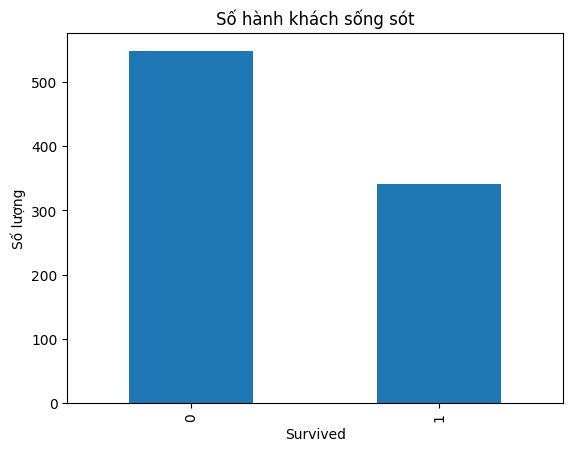

In [42]:
# Số hành khách sống sót / không sống sót
train["Survived"].value_counts().sort_index().plot(kind="bar")
plt.title("Số hành khách sống sót")
plt.xlabel("Survived")
plt.ylabel("Số lượng")
plt.show()

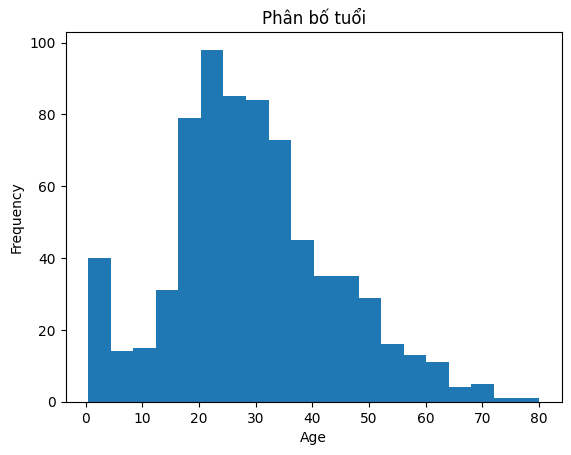

In [43]:
# Phân bố tuổi
train["Age"].plot(kind="hist", bins=20)
plt.title("Phân bố tuổi")
plt.xlabel("Age")
plt.show()

## Data Preprocessing
Để giữ bài đơn giản giống tài liệu PDF, ta sử dụng các thuộc tính:

Pclass, Sex, Age, SibSp, Parch, Fare, Embarked

Các bước:

Điền tuổi thiếu bằng tuổi trung bình.

Điền Fare thiếu bằng giá vé trung bình.

One-hot encoding cho Sex, Embarked, Pclass.

Chuẩn hóa các biến số.

In [44]:
def preprocess_titanic(df):
    data = df.copy()

    # Điền dữ liệu thiếu
    data["Age"] = data["Age"].fillna(data["Age"].mean())
    data["Fare"] = data["Fare"].fillna(data["Fare"].mean())
    data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

    # One-hot encoding
    sex = pd.get_dummies(data["Sex"], prefix="Sex", drop_first=True)
    embark = pd.get_dummies(data["Embarked"], prefix="Embarked", drop_first=True)
    pclass = pd.get_dummies(data["Pclass"], prefix="Pclass", drop_first=True)

    data = pd.concat([data, sex, embark, pclass], axis=1)

    # Bỏ các cột không sử dụng
    data = data.drop(
        ["Pclass", "Sex", "Embarked", "Cabin", "PassengerId", "Name", "Ticket"],
        axis=1
    )

    return data


train_p = preprocess_titanic(train)
test_p = preprocess_titanic(test)

train_p.head()

,Survived,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Pclass_2,Pclass_3
0,0,22.0,1,0,7.2500,True,False,True,False,True
1,1,38.0,1,0,71.2833,False,False,False,False,False
2,1,26.0,0,0,7.9250,False,False,True,False,True
3,1,35.0,1,0,53.1000,False,False,True,False,False
4,0,35.0,0,0,8.0500,True,False,True,False,True


## Đồng bộ cột giữa train và test

In [45]:
X = train_p.drop("Survived", axis=1)
y = train_p["Survived"]

# test không có cột Survived
X_test_kaggle = test_p.copy()

# Đảm bảo train và test có cùng cột
X, X_test_kaggle = X.align(
    X_test_kaggle,
    join="left",
    axis=1,
    fill_value=0
)

print("Các cột đầu vào:")
print(X.columns.tolist())

Các cột đầu vào:
['Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Pclass_2', 'Pclass_3']


## Chia train / validation

In [46]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test_kaggle_scaled = scaler.transform(X_test_kaggle)

print(X_train.shape, X_val.shape)

(623, 9) (268, 9)


## Chuyển sang Tensor

In [47]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)

X_kaggle_t = torch.tensor(X_test_kaggle_scaled, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=32,
    shuffle=True
)

print(X_train_t.shape, y_train_t.shape)

torch.Size([623, 9]) torch.Size([623, 1])


## Define Model

Mạng MLP đơn giản:

Input → Linear → ReLU → Linear → ReLU → Output

In [49]:
class TitanicMLP(nn.Module):
    def __init__(self, input_size, hidden1=32, hidden2=16):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_size, hidden1),
            nn.ReLU(),

            nn.Linear(hidden1, hidden2),
            nn.ReLU(),

            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.net(x)


model = TitanicMLP(X_train.shape[1])

print(model)

TitanicMLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## Fit Model
Dùng:

Loss: BCEWithLogitsLoss
Optimizer: Adam
Epoch: 100
W&B chỉ được dùng để theo dõi loss và accuracy cho đơn giản.

Nếu chưa muốn kết nối W&B, đổi:

WANDB_MODE = "disabled"

In [52]:
import wandb
WANDB_MODE = "disabled"   # đổi thành "online" nếu muốn dùng W&B

run = wandb.init(
    project="titanic-pytorch",
    config={
        "hidden1": 32,
        "hidden2": 16,
        "learning_rate": 0.001,
        "batch_size": 32,
        "epochs": 100
    },
    mode=WANDB_MODE
)

In [53]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 100

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Validation
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_probs = torch.sigmoid(val_logits)
        val_pred = (val_probs >= 0.5).int().numpy().ravel()

    val_acc = accuracy_score(y_val, val_pred)
    avg_loss = total_loss / len(train_loader)

    wandb.log({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "val_accuracy": val_acc
    })

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:3d}/{epochs} - "
            f"Loss: {avg_loss:.4f} - "
            f"Val Acc: {val_acc:.4f}"
        )

wandb.finish()

Epoch  10/100 - Loss: 0.4155 - Val Acc: 0.8172
Epoch  20/100 - Loss: 0.3720 - Val Acc: 0.8134
Epoch  30/100 - Loss: 0.3530 - Val Acc: 0.8246
Epoch  40/100 - Loss: 0.3564 - Val Acc: 0.8246
Epoch  50/100 - Loss: 0.3492 - Val Acc: 0.8097
Epoch  60/100 - Loss: 0.3394 - Val Acc: 0.8284
Epoch  70/100 - Loss: 0.3338 - Val Acc: 0.8209
Epoch  80/100 - Loss: 0.3266 - Val Acc: 0.8172
Epoch  90/100 - Loss: 0.3255 - Val Acc: 0.8209
Epoch 100/100 - Loss: 0.3183 - Val Acc: 0.8134


## Model Evaluation

In [54]:
model.eval()

with torch.no_grad():
    logits = model(X_val_t)
    probs = torch.sigmoid(logits)
    predictions = (probs >= 0.5).int().numpy().ravel()

print(classification_report(y_val, predictions))

              precision    recall  f1-score   support

           0       0.80      0.92      0.86       165
           1       0.84      0.64      0.73       103

    accuracy                           0.81       268
   macro avg       0.82      0.78      0.79       268
weighted avg       0.82      0.81      0.81       268



In [55]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, predictions))

print("\nAccuracy:")
print(accuracy_score(y_val, predictions))

Confusion Matrix:
[[152  13]
 [ 37  66]]

Accuracy:
0.8134328358208955


## Tinh chỉnh tham số mạng đơn giản
Ta thử 3 cấu hình khác nhau thay vì dùng Grid Search phức tạp.

Các tham số được thử:

hidden1
hidden2
learning_rate
Mục tiêu: chọn cấu hình có Accuracy trên validation cao nhất.

In [56]:
configs = [
    {"hidden1": 16, "hidden2": 8,  "lr": 0.001},
    {"hidden1": 32, "hidden2": 16, "lr": 0.001},
    {"hidden1": 64, "hidden2": 32, "lr": 0.001}
]

results = []

for cfg in configs:

    m = TitanicMLP(
        input_size=X_train.shape[1],
        hidden1=cfg["hidden1"],
        hidden2=cfg["hidden2"]
    )

    optimizer = torch.optim.Adam(m.parameters(), lr=cfg["lr"])
    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(50):
        m.train()

        for xb, yb in train_loader:
            optimizer.zero_grad()

            logits = m(xb)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

    m.eval()

    with torch.no_grad():
        pred = (
            torch.sigmoid(m(X_val_t)) >= 0.5
        ).int().numpy().ravel()

    acc = accuracy_score(y_val, pred)

    results.append({
        "hidden1": cfg["hidden1"],
        "hidden2": cfg["hidden2"],
        "lr": cfg["lr"],
        "accuracy": acc,
        "model": m
    })

result_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "model"}
    for r in results
])

result_df

,hidden1,hidden2,lr,accuracy
0,16,8,0.001,0.805970
1,32,16,0.001,0.813433
2,64,32,0.001,0.813433


In [57]:
best_result = max(results, key=lambda x: x["accuracy"])

best_model = best_result["model"]

print("Cấu hình tốt nhất:")
print("hidden1 =", best_result["hidden1"])
print("hidden2 =", best_result["hidden2"])
print("lr      =", best_result["lr"])
print("accuracy=", best_result["accuracy"])

Cấu hình tốt nhất:
hidden1 = 32
hidden2 = 16
lr      = 0.001
accuracy= 0.8134328358208955


## Prediction cho tập test Kaggle

Tập `test.csv` không có nhãn `Survived`.

Ta dùng `best_model` để dự đoán cho toàn bộ 418 hành khách trong tập test.

In [58]:
best_model.eval()

with torch.no_grad():
    test_logits = best_model(X_kaggle_t)

    test_probabilities = torch.sigmoid(test_logits)

    test_predictions = (
        test_probabilities >= 0.5
    ).int().numpy().ravel()

print(test_predictions[:20])
print("Số dự đoán:", len(test_predictions))

[0 0 0 0 0 0 1 0 1 0 0 0 1 0 1 1 0 0 0 0]
Số dự đoán: 418


## Submission

File submission cần có đúng 2 cột:

- `PassengerId`
- `Survived`

Ta lấy `PassengerId` trực tiếp từ `test.csv` và dùng kết quả dự đoán của PyTorch.

In [59]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [60]:
submission.to_csv("submission_pytorch.csv", index=False)

print("Đã tạo file: submission_pytorch.csv")
print("Kích thước:", submission.shape)

Đã tạo file: submission_pytorch.csv
Kích thước: (418, 2)


## Kiểm tra file submission

In [61]:
check_submission = pd.read_csv("submission_pytorch.csv")

print(check_submission.head())
print()
print(check_submission.info())

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  418 non-null    int64
 1   Survived     418 non-null    int64
dtypes: int64(2)
memory usage: 6.7 KB
None


## Kết luận

Quy trình PyTorch trong bài:

**Load Data → Data Analysis → Data Preprocessing → Define Model → Fit Model → Model Evaluation → Tuning → Prediction → Submission**

Điểm khác so với Logistic Regression trong tài liệu mẫu là:

- Mô hình được xây dựng bằng `torch.nn.Module`.
- Huấn luyện bằng vòng lặp PyTorch.
- Dùng `BCEWithLogitsLoss`.
- Dùng `Adam`.
- Dự đoán xác suất bằng `torch.sigmoid`.
- Kết quả cuối cùng được lưu vào `submission_pytorch.csv` để nộp Kaggle.